<img src="../images/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Bachelorarbeit </b> <br> FS 2026 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

# Bachelorarbeit Diagramme

Generiert die Abbildungen fuer die Bachelorarbeit (Kapitel *Datenbeschaffung*) und
speichert sie als PNG unter `images/` im Projekt-Root (nicht unter
`bachelorarbeit/images/` -- dorthin muessen sie nach dem Ausfuehren manuell
hochgeladen werden, da Overleaf nicht direkt an dieses Repo angebunden ist).

Nutzt ausschliesslich bereits vorhandene, lokal gespeicherte Daten
(`assets.parquet`, `asset_daily.parquet`, die OHLCV-Parquet-Dateien) --
es werden keine neuen API-Calls ausgeloest.


---

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches

sys.path.insert(0, str(Path("..").resolve()))
from src.config import ASSETS_PATH, ASSET_DAILY_PATH, OHLCV_DIR, PROJECT_ROOT


## OST-Farbpalette

Die beiden Markenfarben wurden direkt aus `bachelorarbeit/images/OST.png` extrahiert
(haeufigste Pixelfarbe je Logo-Ring), nicht frei gewaehlt:

- **OST Pink** `#D72864` -- Hauptfarbe fuer Einzelserien-Plots (z.B. Zeitreihen).
- **OST Violett** `#8C195F` -- Zweitfarbe, fuer eine zweite Serie oder als Akzent.

Pink und Violett liegen mit einem OKLab-Farbabstand von ca. 16 relativ nah beieinander
(beide aus der Magenta-Familie) und werden deshalb in keinem Chart als konkurrierendes
Kategorie-Paar nebeneinander verwendet -- das waere fuer Rot-Gruen-Sehschwaeche riskant.
Stattdessen bekommt jeder Plot genau eine Markenfarbe als Identitaetsfarbe; eine
"keine Daten"-Kategorie wird ueber ein neutrales Grau mit Schraffur codiert statt ueber
die zweite Markenfarbe.


In [2]:
OST_PINK   = "#D72864"
OST_VIOLET = "#8C195F"
OST_GRAY   = "#B5B5B5"   # neutral, fuer "keine Daten" / Abwesenheit
TEXT_DARK  = "#222222"

IMAGES_DIR = PROJECT_ROOT / "images"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
print(f"Bilder werden gespeichert unter: ./{IMAGES_DIR.relative_to(PROJECT_ROOT)}")


Bilder werden gespeichert unter: ./images


## Abbildung 1: Eligibility ueber die Zeit

Anzahl Assets, die an einem gegebenen Tag Filter 1 (Top 100 nach Marktkapitalisierung
*innerhalb des Kandidatenpools*) und Filter 2 (Handelsvolumen > 50 Mio. USD)
gleichzeitig erfuellen. Siehe `01_data_aquisition/01_assets.ipynb`, Abschnitt 13.


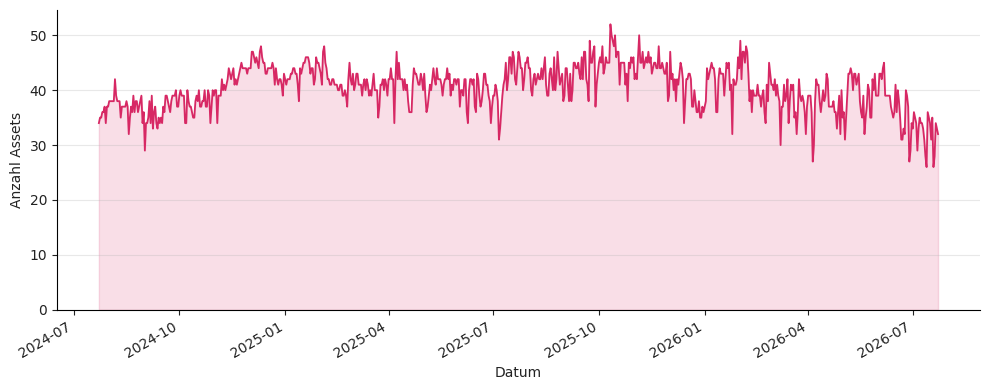

Min: 26 | Max: 52 | Mittelwert: 40.4
Gespeichert: /Users/ryanmikus/Development/Python/00_Quant/26FS_BA/images/eligibility_over_time.png


In [3]:
asset_daily_df = pd.read_parquet(ASSET_DAILY_PATH)
daily_counts = asset_daily_df.groupby("date")["asset_id"].nunique().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pd.to_datetime(daily_counts.index), daily_counts.values, color=OST_PINK, linewidth=1.3)
ax.fill_between(pd.to_datetime(daily_counts.index), daily_counts.values, color=OST_PINK, alpha=0.15)
# Alternative: OST_VIOLETT als Zweitfarbe, siehe Begruendung zur Farbwahl oben --
# OST Pink ist die Standardfarbe fuer alle Plots dieses Notebooks, Violett bleibt
# fuer Ausnahmefaelle (z. B. ein zweiter Chart im selben Dokument) reserviert.
# ax.plot(pd.to_datetime(daily_counts.index), daily_counts.values, color=OST_VIOLET, linewidth=1.3)
# ax.fill_between(pd.to_datetime(daily_counts.index), daily_counts.values, color=OST_VIOLET, alpha=0.15)

# Kein ax.set_title(): Die Bachelorarbeit traegt die Beschreibung ueber die
# LaTeX-Abbildungsbeschriftung (\caption), ein zusaetzlicher Plot-Titel waere doppelt.
ax.set_xlabel("Datum", color=TEXT_DARK)
ax.set_ylabel("Anzahl Assets", color=TEXT_DARK)
ax.tick_params(colors=TEXT_DARK)
ax.grid(True, axis="y", alpha=0.3, color=OST_GRAY)
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.autofmt_xdate()
fig.tight_layout()

out_path = IMAGES_DIR / "eligibility_over_time.png"
fig.savefig(out_path, dpi=200)
plt.show()

print(f"Min: {daily_counts.min()} | Max: {daily_counts.max()} | Mittelwert: {daily_counts.mean():.1f}")
print(f"Gespeichert: {out_path}")


## Abbildung 2: Datenverfuegbarkeit pro Asset

Zeigt fuer jedes der finalen Assets, ab wann 5-Minuten-OHLCV-Daten auf Binance
vorliegen. Assets ohne aufgeloestes `binance_symbol` haben keine OHLCV-Daten und
werden separat schraffiert markiert. Siehe `01_data_aquisition/01_assets.ipynb`
und `02_ohlcv.ipynb`.


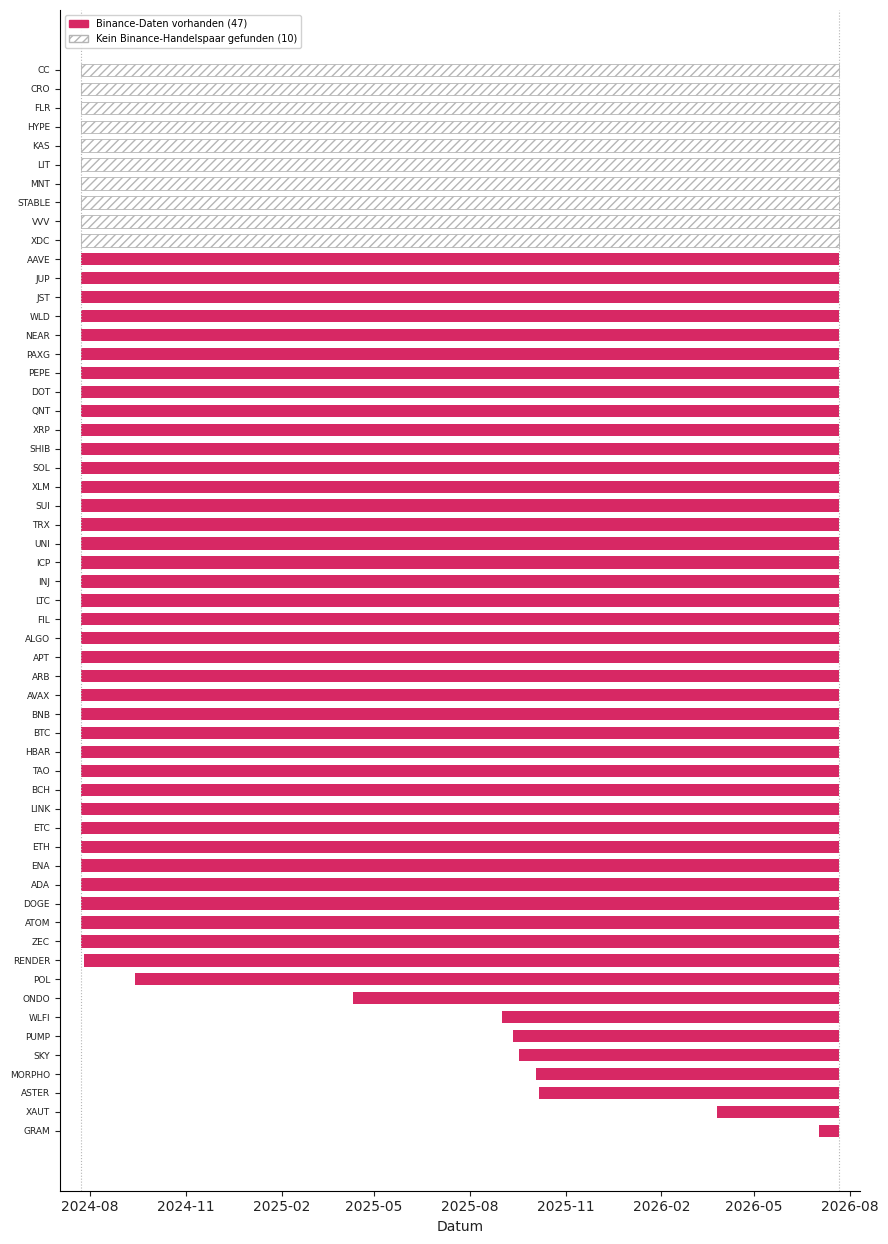

Gespeichert: /Users/ryanmikus/Development/Python/00_Quant/26FS_BA/images/data_coverage.png


In [4]:
assets_df = pd.read_parquet(ASSETS_PATH)

ohlcv_files = sorted(OHLCV_DIR.glob("ohlcv_*.parquet"))
frames = [pd.read_parquet(f, columns=["timestamp", "market_symbol"]) for f in ohlcv_files]
full_ohlcv = pd.concat(frames, ignore_index=True)
full_ohlcv["date"] = pd.to_datetime(full_ohlcv["timestamp"]).dt.date
first_seen = full_ohlcv.groupby("market_symbol")["date"].min()

WINDOW_START = pd.Timestamp("2024-07-23")
WINDOW_END = pd.Timestamp("2026-07-22")

with_symbol = assets_df.loc[assets_df["binance_symbol"].notna(), ["symbol", "binance_symbol"]].copy()
with_symbol["first_seen"] = pd.to_datetime(with_symbol["binance_symbol"].map(first_seen))
with_symbol = with_symbol.sort_values("first_seen", ascending=True).reset_index(drop=True)

without_symbol = assets_df.loc[assets_df["binance_symbol"].isna(), "symbol"].sort_values().tolist()

n_with = len(with_symbol)
n_without = len(without_symbol)
n_total = n_with + n_without

fig, ax = plt.subplots(figsize=(9, max(6, n_total * 0.22)))

y_labels = []
y = 0
for _, row in with_symbol.iloc[::-1].iterrows():
    start = row["first_seen"]
    ax.barh(y, (WINDOW_END - start).days, left=start, height=0.65, color=OST_PINK)
    y_labels.append(row["symbol"])
    y += 1

for sym in sorted(without_symbol, reverse=True):
    ax.barh(y, (WINDOW_END - WINDOW_START).days, left=WINDOW_START, height=0.65,
            facecolor="none", edgecolor=OST_GRAY, hatch="////", linewidth=0.6)
    # Alternative: die zweite OST-Markenfarbe (Violett) statt Grau, siehe
    # Begruendung zur Farbwahl oben -- bewusst nicht aktiv, da Pink+Violett als
    # nebeneinanderstehendes Kategorie-Paar zu nah beieinander liegen (CVD-Risiko).
    # ax.barh(y, (WINDOW_END - WINDOW_START).days, left=WINDOW_START, height=0.65,
    #         facecolor="none", edgecolor=OST_VIOLET, hatch="////", linewidth=0.6)
    y_labels.append(sym)
    y += 1

ax.set_yticks(range(n_total))
ax.set_yticklabels(y_labels, fontsize=6.5, color=TEXT_DARK)
ax.set_xlim(WINDOW_START - pd.Timedelta(days=20), WINDOW_END + pd.Timedelta(days=20))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.axvline(WINDOW_START, color=OST_GRAY, linewidth=0.8, linestyle=":")
ax.axvline(WINDOW_END, color=OST_GRAY, linewidth=0.8, linestyle=":")
ax.tick_params(colors=TEXT_DARK)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ax.set_xlabel("Datum", color=TEXT_DARK)
# Kein ax.set_title(): Beschreibung erfolgt ueber die LaTeX-Abbildungsbeschriftung.

pink_patch = mpatches.Patch(color=OST_PINK, label=f"Binance-Daten vorhanden ({n_with})")
hatch_patch = mpatches.Patch(facecolor="white", edgecolor=OST_GRAY, hatch="////", label=f"Kein Binance-Handelspaar gefunden ({n_without})")
# hatch_patch = mpatches.Patch(facecolor="white", edgecolor=OST_VIOLET, hatch="////", label=f"Kein Binance-Handelspaar gefunden ({n_without})")  # Alternative mit Violett
ax.legend(handles=[pink_patch, hatch_patch], loc="upper left", fontsize=7, framealpha=0.9)

fig.tight_layout()
out_path = IMAGES_DIR / "data_coverage.png"
fig.savefig(out_path, dpi=200)
plt.show()

print(f"Gespeichert: {out_path}")


## Abbildung 3: Basket-Belegung ueber die Zeit

Zeigt fuer die vier fixen Liquiditaets-Baskets (siehe `02_tda_clustering/01_baskets.ipynb`,
Schwellen bei 100 / 250 / 1000 Mio. USD rollierendem 7-Tage-Median-Volumen), wie viele
Assets an jedem Tag im jeweiligen Basket liegen, sowie an welchem Anteil der Tage ein
Basket komplett leer ist (0 Assets).

**Farbwahl**: Nur Basket 4 bekommt die OST-Markenfarbe Pink (`#D72864`) -- er ist der
Basket, der ueberhaupt leer werden kann (siehe Balkendiagramm unten), und wird damit
optisch hervorgehoben. Baskets 1 bis 3 bekommen drei weitere, von Pink klar
unterscheidbare Hues (Blau `#2a78d6`, Gruen `#008300`, Violett `#4a3aa7`), da bei vier
sich staendig kreuzenden Linien jedes Paar irgendwann nebeneinander liegen kann (nicht
nur benachbarte Legenden-Eintraege) und somit alle sechs Paare CVD-sicher unterscheidbar
sein muessen, nicht nur die Reihenfolge in der Legende. Alle sechs Paare wurden in OKLab
geprueft (normal-vision dE, Ziel-Gate >= 15): schlechtestes Paar (Blau/Violett) liegt bei
16.3, alle anderen Paare deutlich darueber. Farben mit zu geringem Kontrast auf Weiss
(z. B. Gelb, ca. 2.2:1) wurden bewusst vermieden, da eine duenne Linie sonst auf dem
weissen Hintergrund kaum sichtbar waere.


In [5]:
from src.clustering.helpers import HelperFunctions
from src.config import ASSET_DAILY_PATH, DATE_COL, VOLUME_COL

helper = HelperFunctions()

LOOKBACK_DAYS = 7
BASKET_UPPER_BOUNDS = [100_000_000, 250_000_000, 1_000_000_000]
BASKET_LABELS = ["Basket 1", "Basket 2", "Basket 3", "Basket 4"]

# Nur Basket 4 bekommt die OST-Markenfarbe Pink (siehe Begruendung oben). Baskets
# 1-3 bekommen drei weitere Hues, die gegen Pink UND untereinander CVD-sicher
# unterscheidbar sind (alle 6 Paare in OKLab geprueft, schlechtestes Paar dE=16.3,
# Ziel-Gate >= 15).
BASKET_RAMP = ["#2a78d6", "#008300", "#4a3aa7", "#D72864"]  # Basket 1, 2, 3, 4

asset_daily_df = pd.read_parquet(ASSET_DAILY_PATH)
asset_daily_df[DATE_COL] = pd.to_datetime(asset_daily_df[DATE_COL])

rolling_volume_df = helper.compute_rolling_volume_table(
    asset_daily_df,
    id_column="asset_id",
    date_column=DATE_COL,
    volume_column=VOLUME_COL,
    lookback_days=LOOKBACK_DAYS,
)

rolling_volume_df["basket"] = rolling_volume_df["rolling_median_volume_24h_usd"].apply(
    lambda volume: helper.assign_volume_basket(volume, basket_upper_bounds=BASKET_UPPER_BOUNDS)
)

basket_counts = (
    rolling_volume_df.dropna(subset=["basket"])
    .groupby([DATE_COL, "basket"], observed=True)
    .size()
    .unstack("basket", fill_value=0)
    .reindex(columns=BASKET_LABELS, fill_value=0)
    .sort_index()
)

empty_share_pct = (basket_counts == 0).mean() * 100
print("Anteil Tage mit leerem Basket (%):")
print(empty_share_pct.round(1).to_string())


Anteil Tage mit leerem Basket (%):
basket
Basket 1    0.0
Basket 2    0.0
Basket 3    0.0
Basket 4    1.7


/var/folders/00/k8c8xvw575l2_kgdcbf1vq8m0000gn/T/ipykernel_16709/1253682135.py:49: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


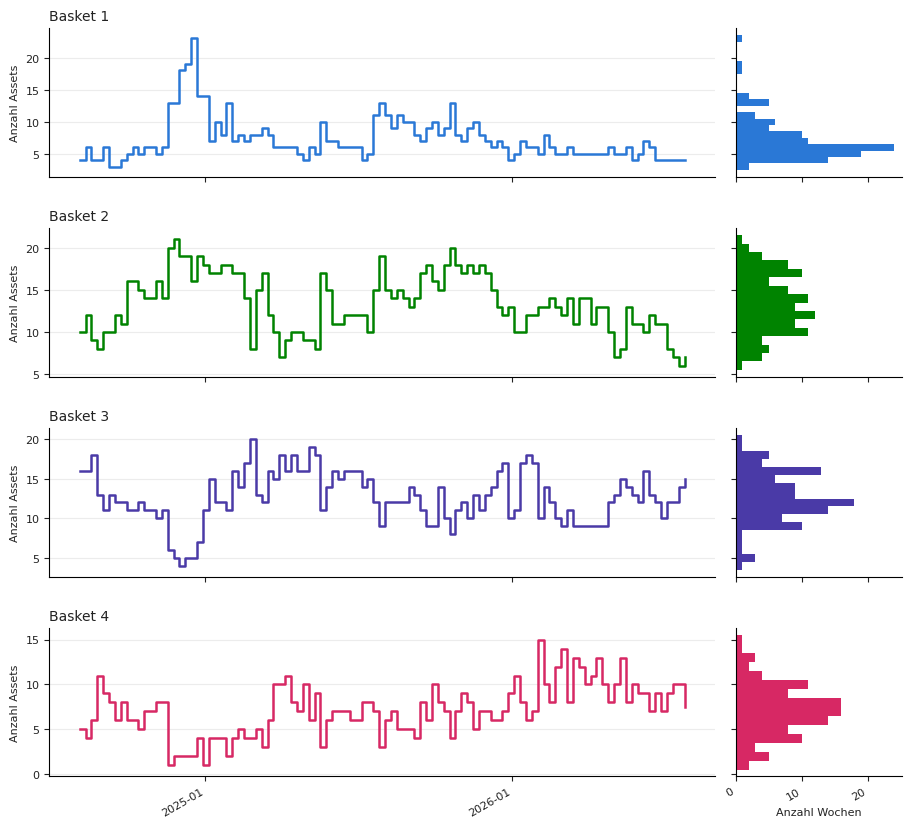

Gespeichert: /Users/ryanmikus/Development/Python/00_Quant/26FS_BA/images/basket_composition.png

Anteil Tage mit leerem Basket (%), zur Referenz:
basket
Basket 1    0.0
Basket 2    0.0
Basket 3    0.0
Basket 4    1.7


In [6]:
# Vier einzelne Plots (ein Basket pro Zeile), links Zeitreihe, rechts gedrehtes
# (horizontales) Histogramm derselben Werte -- beide Achsen teilen sich die
# y-Achse (Anzahl Assets), damit die Histogramm-Balken direkt auf Hoehe der
# Linienwerte liegen. Basis sind weiterhin die woechentlichen Mediane (echte,
# ganzzahlige Tageswerte statt geglaetteter Interpolation, siehe oben).
# Anzahl Assets pro Basket ist zwingend ganzzahlig (diskret) -- woechentlicher
# Median statt gleitendem Mittelwert, damit kein Wert wie "27.3 Assets"
# entsteht: bei einer ungeraden Fenstergroesse (7 Tage) ist der Median IMMER
# einer der sieben tatsaechlich beobachteten Tageswerte.
basket_counts_weekly = basket_counts.resample("W").median()

fig, axes = plt.subplots(
    4, 2, figsize=(11, 11),
    gridspec_kw={"width_ratios": [4, 1], "wspace": 0.05, "hspace": 0.35},
    sharex="col",
)

for row, (label, color) in enumerate(zip(BASKET_LABELS, BASKET_RAMP)):
    ax_line, ax_hist = axes[row, 0], axes[row, 1]
    series = basket_counts_weekly[label]

    ax_line.plot(series.index, series.values, drawstyle="steps-post", color=color, linewidth=1.8)
    # ax_line.set_title(label, ...) bleibt bestehen: identifiziert, welcher der
    # vier Baskets in dieser Zeile gezeigt wird -- das ist keine Dopplung der
    # LaTeX-Abbildungsbeschriftung, sondern noetige Panel-Beschriftung innerhalb
    # des 4x2-Grids (die Caption kann nicht "sagen", welche Zeile welcher Basket ist).
    ax_line.set_title(label, loc="left", fontsize=10, color=TEXT_DARK)
    ax_line.set_ylabel("Anzahl Assets", fontsize=8, color=TEXT_DARK)
    ax_line.tick_params(colors=TEXT_DARK, labelsize=8)
    ax_line.grid(True, axis="y", alpha=0.25, color=OST_GRAY)
    for spine in ["top", "right"]:
        ax_line.spines[spine].set_visible(False)

    bin_edges = np.arange(series.min() - 0.5, series.max() + 1.5, 1)
    ax_hist.hist(series.values, bins=bin_edges, orientation="horizontal", color=color)
    ax_hist.sharey(ax_line)
    ax_hist.set_xlabel("Anzahl Wochen", fontsize=8, color=TEXT_DARK)
    ax_hist.tick_params(colors=TEXT_DARK, labelsize=8)
    plt.setp(ax_hist.get_yticklabels(), visible=False)
    for spine in ["top", "right"]:
        ax_hist.spines[spine].set_visible(False)

axes[-1, 0].xaxis.set_major_locator(mdates.YearLocator())
axes[-1, 0].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig.autofmt_xdate()

# Kein fig.suptitle(): Die Bachelorarbeit traegt die Beschreibung ueber die
# LaTeX-Abbildungsbeschriftung (\caption), ein zusaetzlicher Gesamttitel waere doppelt.
fig.tight_layout()
out_path = IMAGES_DIR / "basket_composition.png"
fig.savefig(out_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"Gespeichert: {out_path}")
print()
print("Anteil Tage mit leerem Basket (%), zur Referenz:")
print(empty_share_pct.round(1).to_string())


## Abbildung 3b: Basket-Belegung als Boxplot

Alternative Darstellung derselben Verteilung als Boxplot, ein Basket pro Box.
Basis sind hier die vollen taeglichen Basket-Groessen (`basket_counts`, nicht die
woechentlichen Mediane aus Abbildung 3) -- ein Boxplot soll die tatsaechliche
Streuung der Verteilung zeigen, die woechentliche Median-Glaettung wuerde
Tagesvarianz kuenstlich wegglaetten und die Anzahl Datenpunkte von ca. 730 auf
ca. 104 reduzieren, ohne dass hier (anders als bei Abbildung 3) ein Interpolations-
Argument dagegen spricht: taegliche Werte sind bereits ganzzahlig. Da hier vier
Boxen nebeneinander stehen -- die Position auf der x-Achse traegt die
Kategorie-Identitaet, nicht die Farbe --, reicht eine einzelne Farbe fuer alle
vier Boxen. Durchgehend OST Pink.


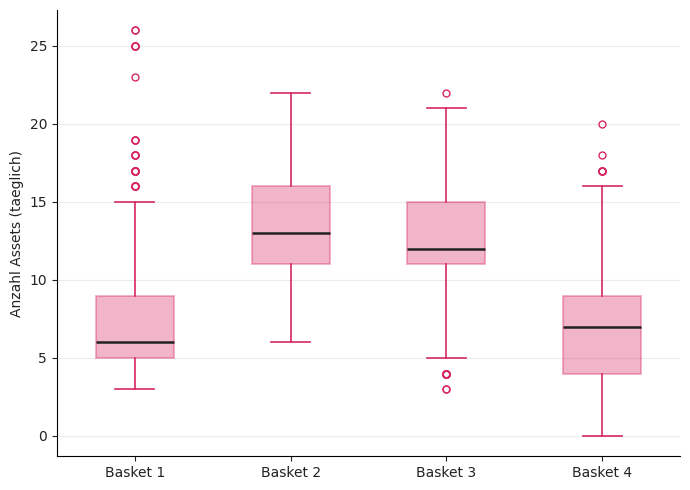

Gespeichert: /Users/ryanmikus/Development/Python/00_Quant/26FS_BA/images/basket_boxplot.png
Datenpunkte pro Box: 725


In [7]:
fig, ax = plt.subplots(figsize=(7, 5))

box_data = [basket_counts[label].values for label in BASKET_LABELS]
bp = ax.boxplot(
    box_data,
    labels=BASKET_LABELS,
    patch_artist=True,
    widths=0.5,
    medianprops={"color": TEXT_DARK, "linewidth": 1.8},
    whiskerprops={"color": OST_PINK, "linewidth": 1.2},
    capprops={"color": OST_PINK, "linewidth": 1.2},
    flierprops={"markeredgecolor": OST_PINK, "markersize": 5, "marker": "o"},
)
for box in bp["boxes"]:
    box.set(facecolor=OST_PINK, alpha=0.35, edgecolor=OST_PINK, linewidth=1.4)

ax.set_ylabel("Anzahl Assets (taeglich)", color=TEXT_DARK)
# Kein ax.set_title(): Beschreibung erfolgt ueber die LaTeX-Abbildungsbeschriftung.
ax.tick_params(colors=TEXT_DARK)
ax.grid(True, axis="y", alpha=0.25, color=OST_GRAY)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

fig.tight_layout()
out_path = IMAGES_DIR / "basket_boxplot.png"
fig.savefig(out_path, dpi=200)
plt.show()

print(f"Gespeichert: {out_path}")
print(f"Datenpunkte pro Box: {len(basket_counts)}")


## Abbildung 4: Beispiel BTC, ETH, SOL -- Dendrogramm

Reproduziert das Beispiel aus `Topologie.tex` (Abschnitt "Clustering-Algorithmus"):
Basket 1, 7-Tage-Fenster endend am 15.06.2025.


In [8]:
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers 3D projection)

ASSET_COLORS = {"BTC": OST_PINK, "ETH": "#2a78d6", "SOL": "#008300"}

EXAMPLE_END = pd.Timestamp("2025-06-15", tz="UTC")
EXAMPLE_START = EXAMPLE_END - pd.Timedelta(days=7)

_assets_df = pd.read_parquet(ASSETS_PATH)
_symbol_map = _assets_df.set_index("symbol")["binance_symbol"].to_dict()
_wanted = {sym: _symbol_map[sym] for sym in ["BTC", "ETH", "SOL"]}

_example_files = sorted(OHLCV_DIR.glob("ohlcv_2025-0[56].parquet"))
_frames = [pd.read_parquet(f, columns=["timestamp", "market_symbol", "close"]) for f in _example_files]
_ohlcv = pd.concat(_frames, ignore_index=True)
_ohlcv["timestamp"] = pd.to_datetime(_ohlcv["timestamp"], utc=True)
_ohlcv = _ohlcv.loc[_ohlcv["market_symbol"].isin(_wanted.values())]
_ohlcv = _ohlcv.loc[(_ohlcv["timestamp"] > EXAMPLE_START) & (_ohlcv["timestamp"] <= EXAMPLE_END)]

example_price = (
    _ohlcv.pivot_table(index="timestamp", columns="market_symbol", values="close", aggfunc="last")
    .sort_index()
    .rename(columns={v: k for k, v in _wanted.items()})[["BTC", "ETH", "SOL"]]
)
example_returns = example_price.pct_change().dropna()
print(f"Beispielfenster: {example_returns.index.min()} bis {example_returns.index.max()}, {len(example_returns)} Zeitpunkte")


Beispielfenster: 2025-06-08 00:10:00+00:00 bis 2025-06-15 00:00:00+00:00, 2015 Zeitpunkte


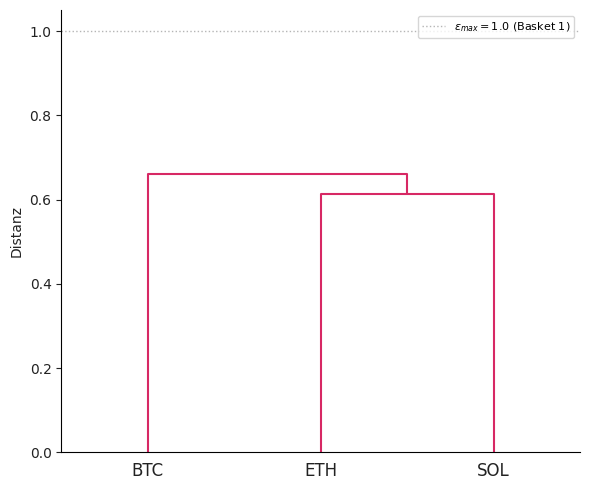

Gespeichert: /Users/ryanmikus/Development/Python/00_Quant/26FS_BA/images/example_dendrogram.png

Korrelationsmatrix:
market_symbol     BTC     ETH     SOL
market_symbol                        
BTC            1.0000  0.7822  0.7796
ETH            0.7822  1.0000  0.8113
SOL            0.7796  0.8113  1.0000

Distanzmatrix:
market_symbol     BTC     ETH     SOL
market_symbol                        
BTC            0.0000  0.6600  0.6639
ETH            0.6600  0.0000  0.6143
SOL            0.6639  0.6143  0.0000


In [9]:
example_corr = example_returns.corr(method="pearson")
example_dist = np.sqrt(2 * (1 - example_corr))

Z_example = linkage(squareform(example_dist.values, checks=False), method="single")

fig, ax = plt.subplots(figsize=(6, 5))
dendrogram(
    Z_example, labels=example_dist.columns.tolist(), ax=ax,
    color_threshold=0, above_threshold_color=OST_PINK,
)
# Kein ax.set_title(): Beschreibung erfolgt ueber die LaTeX-Abbildungsbeschriftung.
ax.set_ylabel("Distanz", color=TEXT_DARK)
ax.tick_params(colors=TEXT_DARK)
ax.axhline(1.0, color=OST_GRAY, linestyle=":", linewidth=1, label=r"$\epsilon_{max}=1.0$ (Basket 1)")
ax.set_ylim(0, 1.05)
ax.legend(fontsize=8, loc="upper right")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()

out_path = IMAGES_DIR / "example_dendrogram.png"
fig.savefig(out_path, dpi=200)
plt.show()
print(f"Gespeichert: {out_path}")

print()
print("Korrelationsmatrix:")
print(example_corr.round(4))
print()
print("Distanzmatrix:")
print(example_dist.round(4))


## Abbildung 4b: Korrelationsmatrix, Distanzmatrix und Dendrogramm nebeneinander (echtes Basket-1-Beispiel)

Ergaenzt Abbildung 4 um eine visuelle Gegenueberstellung aller drei Zwischenschritte
des Clustering-Algorithmus: Korrelationsmatrix (Pearson, aus 5-Min-Returns), die
daraus abgeleitete Distanzmatrix ($d(i,j) = \sqrt{2(1-\rho(i,j))}$, siehe
`HelperFunctions.correlation_distance`) und das resultierende Single-Linkage-
Dendrogramm. Anders als Abbildung 4 (fest vorgegebenes BTC/ETH/SOL-Beispiel) wird
die Basket-1-Zugehoerigkeit hier tatsaechlich ueber `build_volume_baskets`
berechnet -- fuer ein Datum, an dem Basket 1 nur 4 Assets enthaelt (09.06.2025:
BTC, ETH, SOL, XRP), nahe am Zeitpunkt aus Abbildung 4 (15.06.2025) und mit
ueberlappender Asset-Auswahl, aber real aus der Datenpipeline abgeleitet statt
hartkodiert. Gleiches 7-Tage-Fenster wie in Abbildung 4.


In [10]:
from src.clustering.helpers import HelperFunctions
from src.config import DATE_COL, VOLUME_COL

helper_4b = HelperFunctions()
LOOKBACK_DAYS_4B = 7
BASKET_UPPER_BOUNDS_4B = [100_000_000, 250_000_000, 1_000_000_000]

assets_df_4b = pd.read_parquet(ASSETS_PATH)
asset_daily_df_4b = pd.read_parquet(ASSET_DAILY_PATH)
asset_daily_df_4b[DATE_COL] = pd.to_datetime(asset_daily_df_4b[DATE_COL])

rolling_volume_df_4b = helper_4b.compute_rolling_volume_table(
    asset_daily_df_4b, id_column="asset_id", date_column=DATE_COL,
    volume_column=VOLUME_COL, lookback_days=LOOKBACK_DAYS_4B,
)

# Datum bewusst gewaehlt: Basket 1 enthaelt an diesem Tag nur 4 Assets (nicht
# hartkodiert -- ueber die echte Basket-Zuordnungslogik ermittelt), nahe an
# Abbildung 4s Beispieldatum (15.06.2025).
BASKET1_DATE = pd.Timestamp("2025-06-09")
basket1_df = helper_4b.build_volume_baskets(
    rolling_volume_df_4b, BASKET1_DATE, id_column="asset_id", date_column=DATE_COL,
    basket_upper_bounds=BASKET_UPPER_BOUNDS_4B,
)
basket1_members = basket1_df.loc[basket1_df["basket"] == "Basket 1"].merge(
    assets_df_4b[["asset_id", "symbol", "binance_symbol"]], on="asset_id",
)

print(f"Basket 1 am {BASKET1_DATE.date()}: {basket1_members['symbol'].tolist()} ({len(basket1_members)} Assets)")
display(basket1_members[["symbol", "rolling_median_volume_24h_usd"]])


Basket 1 am 2025-06-09: ['BTC', 'ETH', 'SOL', 'XRP'] (4 Assets)


,symbol,rolling_median_volume_24h_usd
0,BTC,2.592566e+10
1,ETH,1.595501e+10
2,SOL,3.081994e+09
3,XRP,1.856646e+09


In [11]:
FIG4B_END = pd.Timestamp("2025-06-09", tz="UTC")
FIG4B_START = FIG4B_END - pd.Timedelta(days=7)

fig4b_symbol_map = dict(zip(basket1_members["symbol"], basket1_members["binance_symbol"]))
fig4b_wanted_binance = set(fig4b_symbol_map.values())

fig4b_files = sorted(OHLCV_DIR.glob("ohlcv_2025-0[56].parquet"))
fig4b_frames = [pd.read_parquet(f, columns=["timestamp", "market_symbol", "close"]) for f in fig4b_files]
fig4b_ohlcv = pd.concat(fig4b_frames, ignore_index=True)
fig4b_ohlcv["timestamp"] = pd.to_datetime(fig4b_ohlcv["timestamp"], utc=True)
fig4b_ohlcv = fig4b_ohlcv.loc[fig4b_ohlcv["market_symbol"].isin(fig4b_wanted_binance)]
fig4b_ohlcv = fig4b_ohlcv.loc[(fig4b_ohlcv["timestamp"] > FIG4B_START) & (fig4b_ohlcv["timestamp"] <= FIG4B_END)]

fig4b_price = (
    fig4b_ohlcv.pivot_table(index="timestamp", columns="market_symbol", values="close", aggfunc="last")
    .sort_index()
    .rename(columns={v: k for k, v in fig4b_symbol_map.items()})[list(fig4b_symbol_map.keys())]
)
fig4b_returns = fig4b_price.pct_change().dropna()
print(f"Fenster: {fig4b_returns.index.min()} bis {fig4b_returns.index.max()}, "
      f"{len(fig4b_returns)} Zeitpunkte, Assets: {list(fig4b_returns.columns)}")

fig4b_corr = fig4b_returns.corr(method="pearson")
fig4b_dist = pd.DataFrame(
    helper_4b.correlation_distance(fig4b_returns),
    index=fig4b_corr.index, columns=fig4b_corr.columns,
)
fig4b_Z = linkage(squareform(fig4b_dist.values, checks=False), method="single")


Fenster: 2025-06-02 00:10:00+00:00 bis 2025-06-09 00:00:00+00:00, 2015 Zeitpunkte, Assets: ['BTC', 'ETH', 'SOL', 'XRP']


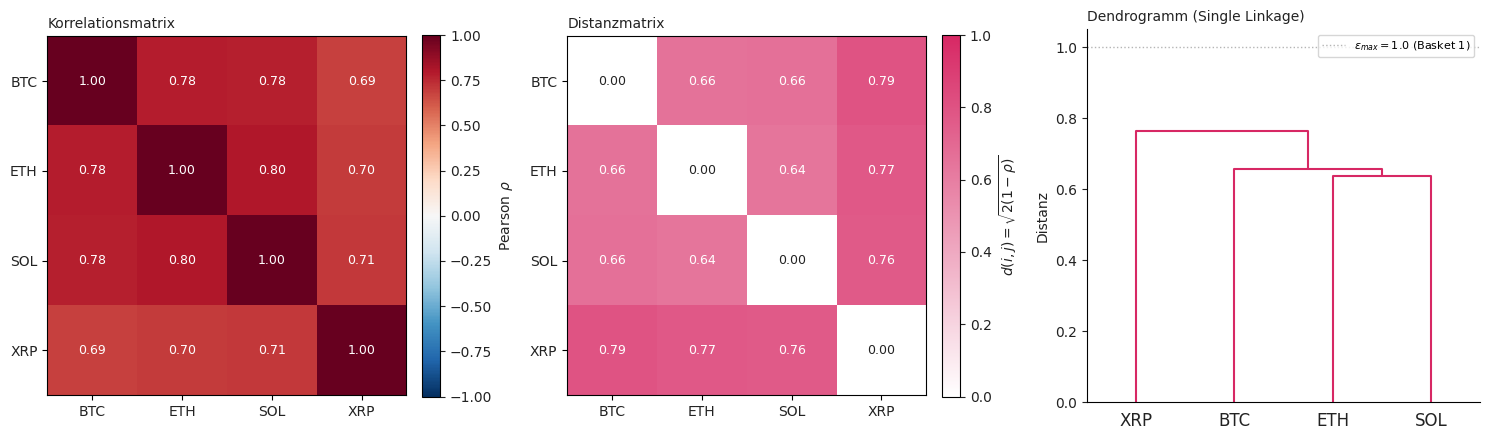

Gespeichert: /Users/ryanmikus/Development/Python/00_Quant/26FS_BA/images/basket1_corr_dist_dendrogram.png


In [12]:
from matplotlib.colors import LinearSegmentedColormap

# Sequenzieller Farbverlauf fuer die Distanzmatrix: ein Hue (OST Pink), hell -> dunkel.
# Korrelationsmatrix bekommt bewusst KEINE Markenfarbe, sondern eine divergierende
# Skala (zwei Hues + neutraler Mittelpunkt bei 0) -- Korrelation hat ein Vorzeichen,
# eine Sequential-Skala wuerde negative und schwach-positive Werte visuell verwechselbar machen.
DIST_CMAP = LinearSegmentedColormap.from_list("ost_pink_seq", ["#FFFFFF", OST_PINK])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Panel 1: Korrelationsmatrix
ax_corr = axes[0]
im_corr = ax_corr.imshow(fig4b_corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax_corr.set_xticks(range(len(fig4b_corr.columns)))
ax_corr.set_xticklabels(fig4b_corr.columns, color=TEXT_DARK)
ax_corr.set_yticks(range(len(fig4b_corr.index)))
ax_corr.set_yticklabels(fig4b_corr.index, color=TEXT_DARK)
for i in range(len(fig4b_corr)):
    for j in range(len(fig4b_corr)):
        val = fig4b_corr.values[i, j]
        ax_corr.text(j, i, f"{val:.2f}", ha="center", va="center",
                      color="white" if abs(val) > 0.6 else TEXT_DARK, fontsize=9)
ax_corr.set_title("Korrelationsmatrix", loc="left", fontsize=10, color=TEXT_DARK)
cbar_corr = fig.colorbar(im_corr, ax=ax_corr, fraction=0.046, pad=0.04)
cbar_corr.set_label(r"Pearson $\rho$", color=TEXT_DARK)
cbar_corr.ax.tick_params(colors=TEXT_DARK)

# Panel 2: Distanzmatrix -- vmax=1.0 bewusst an epsilon_max (Dendrogramm-Schwelle) angelehnt
ax_dist = axes[1]
im_dist = ax_dist.imshow(fig4b_dist.values, cmap=DIST_CMAP, vmin=0, vmax=1.0)
ax_dist.set_xticks(range(len(fig4b_dist.columns)))
ax_dist.set_xticklabels(fig4b_dist.columns, color=TEXT_DARK)
ax_dist.set_yticks(range(len(fig4b_dist.index)))
ax_dist.set_yticklabels(fig4b_dist.index, color=TEXT_DARK)
for i in range(len(fig4b_dist)):
    for j in range(len(fig4b_dist)):
        val = fig4b_dist.values[i, j]
        ax_dist.text(j, i, f"{val:.2f}", ha="center", va="center",
                      color="white" if val > 0.55 else TEXT_DARK, fontsize=9)
ax_dist.set_title("Distanzmatrix", loc="left", fontsize=10, color=TEXT_DARK)
cbar_dist = fig.colorbar(im_dist, ax=ax_dist, fraction=0.046, pad=0.04)
cbar_dist.set_label(r"$d(i,j)=\sqrt{2(1-\rho)}$", color=TEXT_DARK)
cbar_dist.ax.tick_params(colors=TEXT_DARK)

# Panel 3: Dendrogramm, gleicher Stil wie Abbildung 4
ax_dendro = axes[2]
dendrogram(
    fig4b_Z, labels=fig4b_dist.columns.tolist(), ax=ax_dendro,
    color_threshold=0, above_threshold_color=OST_PINK,
)
ax_dendro.set_ylabel("Distanz", color=TEXT_DARK)
ax_dendro.tick_params(colors=TEXT_DARK)
ax_dendro.axhline(1.0, color=OST_GRAY, linestyle=":", linewidth=1, label=r"$\epsilon_{max}=1.0$ (Basket 1)")
ax_dendro.set_ylim(0, 1.05)
ax_dendro.legend(fontsize=8, loc="upper right")
ax_dendro.set_title("Dendrogramm (Single Linkage)", loc="left", fontsize=10, color=TEXT_DARK)
for spine in ["top", "right"]:
    ax_dendro.spines[spine].set_visible(False)

# Kein fig.suptitle(): Beschreibung erfolgt ueber die LaTeX-Abbildungsbeschriftung.
fig.tight_layout()
out_path = IMAGES_DIR / "basket1_corr_dist_dendrogram.png"
fig.savefig(out_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Gespeichert: {out_path}")


## Setup: Daten fuer Abbildungen 5 und 5b

Laedt Basket-/Preisdaten und bestimmt den Kalibrierungszeitraum (erste 80 % der
Historie) einmalig fuer die zwei folgenden, darauf aufbauenden Abbildungen
(Persistenzverteilung, Cluster-Groesse im Zeitverlauf).

In [13]:
from src.clustering.helpers import HelperFunctions, STABLECOIN_SYMBOLS
from src.config import ASSETS_PATH, ASSET_DAILY_PATH, OHLCV_DIR, DATE_COL, ASSET_ID_COL, TIMESTAMP_COL, CLOSE_COL

helper = HelperFunctions()
BASKET_UPPER_BOUNDS = [100_000_000, 250_000_000, 1_000_000_000]
BASKET_LABELS = ["Basket 1", "Basket 2", "Basket 3", "Basket 4"]
EPSILON_CAP = 1.0

assets_df = pd.read_parquet(ASSETS_PATH)
asset_daily_df = pd.read_parquet(ASSET_DAILY_PATH)
asset_daily_df[DATE_COL] = pd.to_datetime(asset_daily_df[DATE_COL], utc=True)

stablecoin_ids = set(assets_df.loc[assets_df["symbol"].isin(STABLECOIN_SYMBOLS), "asset_id"])
all_asset_ids = set(asset_daily_df[ASSET_ID_COL].unique())

# Volles OHLCV (alle Symbole, mit Schlusskursen) fuer die Punktwolken-Konstruktion.
_ohlcv_files = sorted(OHLCV_DIR.glob("ohlcv_*.parquet"))
_frames = [pd.read_parquet(f, columns=["timestamp", "market_symbol", "close"]) for f in _ohlcv_files]
_raw = pd.concat(_frames, ignore_index=True)
_raw["timestamp"] = pd.to_datetime(_raw["timestamp"], utc=True)
_raw = _raw.merge(assets_df[["asset_id", "binance_symbol"]], left_on="market_symbol", right_on="binance_symbol", how="inner")
ohlcv_df = _raw.rename(columns={"timestamp": TIMESTAMP_COL, "close": CLOSE_COL})[[TIMESTAMP_COL, ASSET_ID_COL, CLOSE_COL]].copy()

rolling_volume_df = helper.compute_rolling_volume_table(
    asset_daily_df, id_column=ASSET_ID_COL, date_column=DATE_COL,
    volume_column="global_volume_24h_usd", lookback_days=7,
)

# Kalibrierungszeitraum: erste 80 % der Historie (letzte 20 % bleiben dem Backtest vorbehalten).
data_min, data_max = asset_daily_df[DATE_COL].min(), asset_daily_df[DATE_COL].max()
calibration_end = data_min + (data_max - data_min) * 0.8

print(f"Kalibrierungszeitraum: {data_min.date()} bis {calibration_end.date()}")


Kalibrierungszeitraum: 2024-07-23 bis 2026-02-27


## Abbildung 5: Verteilung der Persistenzwerte, alle vier Baskets

Reproduziert die Kalibrierung der Persistenzschwelle aus `02_tda_clustering/02_pointclouds.ipynb`,
Abschnitt 4: Ueber viele Stichtage im Kalibrierungszeitraum werden pro Basket
(mit dem jeweils kalibrierten Lookback) die Persistenzwerte ALLER Kandidaten-Knoten
gesammelt, nicht nur des jeweiligen Gewinners, um die Verteilung aus Rauschen und
potenziell echtem Signal sichtbar zu machen. Markiert ist je Basket das
90.\,Perzentil, das als Persistenzschwelle verwendet wird.


In [14]:
BASKET_LOOKBACKS = {"Basket 1": 7, "Basket 2": 10, "Basket 3": 15, "Basket 4": 5}
PERSISTENCE_STRIDE_DAYS = 3

persistence_sample_dates = pd.date_range(data_min, calibration_end, freq=f"{PERSISTENCE_STRIDE_DAYS}D", tz="UTC")

persistence_values_by_basket: dict[str, list[float]] = {label: [] for label in BASKET_LABELS}
threshold_90_by_basket: dict[str, float] = {}

for label in BASKET_LABELS:
    lookback = BASKET_LOOKBACKS[label]
    for t in persistence_sample_dates:
        basket_df_at_t = helper.build_volume_baskets(
            rolling_volume_df, t.normalize(), id_column=ASSET_ID_COL, date_column=DATE_COL,
            basket_upper_bounds=BASKET_UPPER_BOUNDS,
        )
        basket_asset_ids = set(basket_df_at_t.loc[basket_df_at_t["basket"] == label, ASSET_ID_COL])
        if len(basket_asset_ids) < 2:
            continue

        exclude_ids = stablecoin_ids | (all_asset_ids - basket_asset_ids)
        res = helper.build_point_cloud(
            ohlcv_df=ohlcv_df, universe_df=asset_daily_df, end_date=t,
            window_size_days=lookback, exclude_asset_ids=exclude_ids,
        )
        if res is None or res["n_dimensions"] < 2:
            continue

        dist = helper.correlation_distance(pd.DataFrame(res["point_cloud"]))
        persistence_values_by_basket[label].extend(helper.get_all_node_persistences(dist, epsilon_cap=EPSILON_CAP))

    threshold_90_by_basket[label] = float(np.percentile(persistence_values_by_basket[label], 90))
    print(f"{label} (Lookback {lookback}): {len(persistence_values_by_basket[label])} Kandidaten-Persistenzwerte, 90. Perzentil = {threshold_90_by_basket[label]:.4f}")


Basket 1 (Lookback 7): 1280 Kandidaten-Persistenzwerte, 90. Perzentil = 0.1916


Basket 2 (Lookback 10): 2026 Kandidaten-Persistenzwerte, 90. Perzentil = 0.1085


Basket 3 (Lookback 15): 1820 Kandidaten-Persistenzwerte, 90. Perzentil = 0.1232


Basket 4 (Lookback 5): 662 Kandidaten-Persistenzwerte, 90. Perzentil = 0.2443


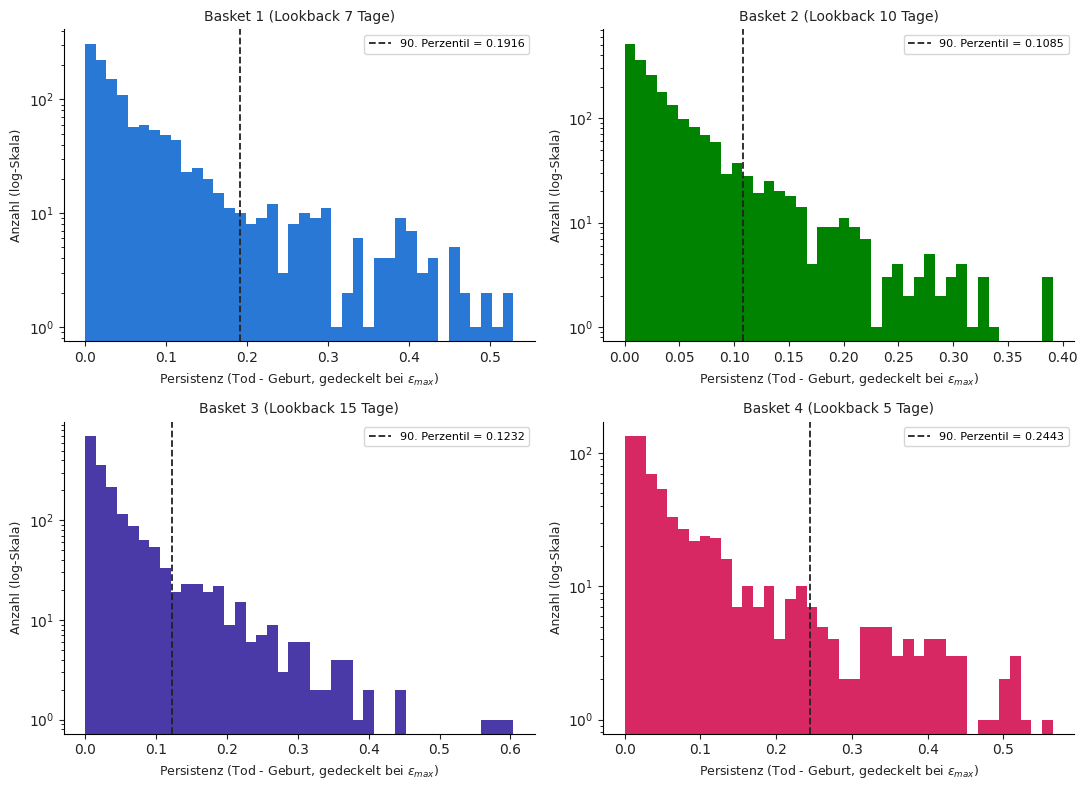

Gespeichert: /Users/ryanmikus/Development/Python/00_Quant/26FS_BA/images/persistence_histogram.png


In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, label, color in zip(axes.flat, BASKET_LABELS, BASKET_RAMP):
    values = persistence_values_by_basket[label]
    threshold = threshold_90_by_basket[label]

    ax.hist(values, bins=40, color=color)
    ax.set_yscale("log")
    ax.axvline(threshold, color=TEXT_DARK, linestyle="--", linewidth=1.3, label=f"90. Perzentil = {threshold:.4f}")

    # ax.set_title(...) bleibt bestehen: identifiziert, welcher Basket in diesem
    # Panel gezeigt wird -- noetige Panel-Beschriftung im 2x2-Grid, keine Dopplung
    # der LaTeX-Abbildungsbeschriftung.
    ax.set_title(f"{label} (Lookback {BASKET_LOOKBACKS[label]} Tage)", fontsize=10, color=TEXT_DARK)
    ax.set_xlabel("Persistenz (Tod - Geburt, gedeckelt bei $\\epsilon_{max}$)", fontsize=9, color=TEXT_DARK)
    ax.set_ylabel("Anzahl (log-Skala)", fontsize=9, color=TEXT_DARK)
    ax.tick_params(colors=TEXT_DARK)
    ax.legend(fontsize=8, loc="upper right")
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

# Kein fig.suptitle(): Die Bachelorarbeit traegt die Beschreibung ueber die
# LaTeX-Abbildungsbeschriftung (\caption), ein zusaetzlicher Gesamttitel waere doppelt.
fig.tight_layout()

out_path = IMAGES_DIR / "persistence_histogram.png"
fig.savefig(out_path, dpi=200)
plt.show()
print(f"Gespeichert: {out_path}")

## Abbildung 5b: Cluster-Groesse je Basket im Zeitverlauf

Im Unterschied zu Abbildung 3 (Basket-*Mitgliedschaft*, also wie viele Assets die
jeweilige Volumen-Schwelle erfuellen) zeigt diese Abbildung die tatsaechlich
extrahierte Cluster-Groesse je Basket: Fuer jeden Tag im vollen Betrachtungszeitraum
wird mit den kalibrierten Basket-Parametern (Lookback und Persistenzschwelle je Basket
aus Abbildung 5, $\epsilon_{max}=1.0$) die Punktwolke gebaut und der groesste Cluster
ueber der Persistenzschwelle extrahiert. Liegt kein Cluster ueber der Schwelle (oder hat
der Basket an diesem Tag weniger als zwei Assets), gilt der Tag als "kein Cluster"
(Cluster-Groesse 0) -- das ist die Groesse, die tatsaechlich bestimmt, ob an einem Tag
ein handelbares Paar hervorgehen kann, nicht die blosse Basket-Mitgliedschaft. Die
gestrichelte vertikale Linie markiert das Ende des Kalibrierungszeitraums (erste 80 %
der Historie, siehe `02_pointclouds.ipynb`); rechts davon liegt der reine
Backtest-Zeitraum, auf dem weder Lookback noch Persistenzschwelle mitbestimmt wurden.


In [16]:
cluster_size_by_basket: dict[str, pd.Series] = {}
no_cluster_share_by_basket: dict[str, float] = {}

full_sample_dates = pd.date_range(data_min, data_max, freq="1D", tz="UTC")

for label in BASKET_LABELS:
    lookback = BASKET_LOOKBACKS[label]
    threshold = threshold_90_by_basket[label]

    records = []
    for t in full_sample_dates:
        basket_df_at_t = helper.build_volume_baskets(
            rolling_volume_df, t.normalize(), id_column=ASSET_ID_COL, date_column=DATE_COL,
            basket_upper_bounds=BASKET_UPPER_BOUNDS,
        )
        basket_asset_ids = set(basket_df_at_t.loc[basket_df_at_t["basket"] == label, ASSET_ID_COL])
        if len(basket_asset_ids) < 2:
            records.append((t, 0))
            continue

        exclude_ids = stablecoin_ids | (all_asset_ids - basket_asset_ids)
        res = helper.build_point_cloud(
            ohlcv_df=ohlcv_df, universe_df=asset_daily_df, end_date=t,
            window_size_days=lookback, exclude_asset_ids=exclude_ids,
        )
        if res is None or res["n_dimensions"] < 2:
            records.append((t, 0))
            continue

        dist = helper.correlation_distance(pd.DataFrame(res["point_cloud"]))
        clusters, _ = helper.get_persistent_clusters(
            dist, res["asset_ids"], persistence_threshold=threshold, epsilon_cap=EPSILON_CAP,
        )
        records.append((t, len(clusters[0]["asset_ids"]) if clusters else 0))

    series = pd.DataFrame(records, columns=[DATE_COL, "cluster_size"]).set_index(DATE_COL)["cluster_size"]
    cluster_size_by_basket[label] = series
    no_cluster_share_by_basket[label] = float((series == 0).mean() * 100)

    print(f"{label} (Lookback {lookback}, Schwelle {threshold:.4f}): "
          f"{int((series == 0).sum())}/{len(series)} Tage ohne Cluster ({no_cluster_share_by_basket[label]:.1f}%)")


Basket 1 (Lookback 7, Schwelle 0.1916): 199/731 Tage ohne Cluster (27.2%)


Basket 2 (Lookback 10, Schwelle 0.1085): 125/731 Tage ohne Cluster (17.1%)


Basket 3 (Lookback 15, Schwelle 0.1232): 260/731 Tage ohne Cluster (35.6%)


Basket 4 (Lookback 5, Schwelle 0.2443): 514/731 Tage ohne Cluster (70.3%)


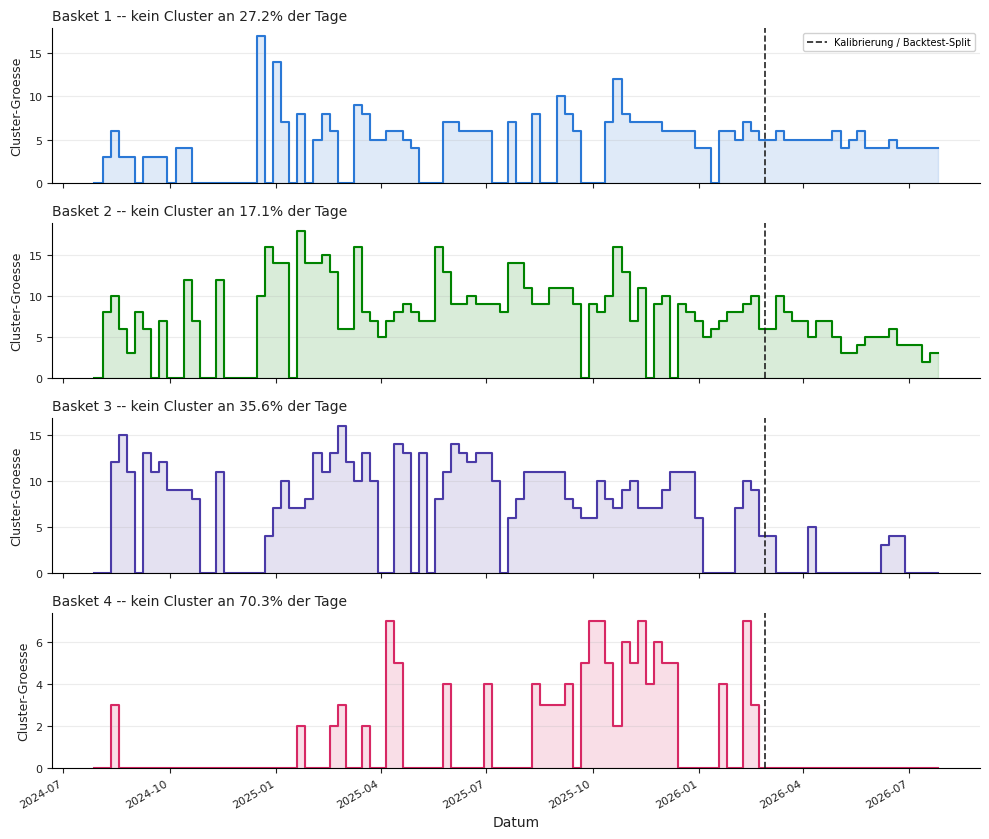

Gespeichert: /Users/ryanmikus/Development/Python/00_Quant/26FS_BA/images/cluster_size_over_time.png
Kalibrierungsende (Data Split): 2026-02-27


In [17]:
from matplotlib.lines import Line2D

# Woechentlicher Median wie bei den anderen Zeitverlaufs-Abbildungen (ganzzahlig,
# keine geglaettete Interpolation). Cluster-Groesse 0 ("kein Cluster") ist ein
# echter, haeufiger Beobachtungswert und geht als solcher in den Median ein.
cluster_size_weekly_by_basket = {label: s.resample("W").median() for label, s in cluster_size_by_basket.items()}

fig, axes = plt.subplots(4, 1, figsize=(10, 8.5), sharex=True)

for ax, label, color in zip(axes, BASKET_LABELS, BASKET_RAMP):
    series = cluster_size_weekly_by_basket[label]
    ax.plot(series.index, series.values, drawstyle="steps-post", color=color, linewidth=1.5)
    ax.fill_between(series.index, series.values, step="post", color=color, alpha=0.15)
    ax.axvline(calibration_end, color=TEXT_DARK, linestyle="--", linewidth=1.2)

    # ax.set_title(...) bleibt bestehen: identifiziert, welcher Basket in dieser
    # Zeile gezeigt wird, inkl. der Leerquote -- noetige Panel-Beschriftung im
    # 4x1-Grid, keine Dopplung der LaTeX-Abbildungsbeschriftung.
    ax.set_title(f"{label} -- kein Cluster an {no_cluster_share_by_basket[label]:.1f}% der Tage",
                 loc="left", fontsize=10, color=TEXT_DARK)
    ax.set_ylabel("Cluster-Groesse", fontsize=9, color=TEXT_DARK)
    ax.tick_params(colors=TEXT_DARK, labelsize=8)
    ax.grid(True, axis="y", alpha=0.25, color=OST_GRAY)
    ax.set_ylim(bottom=0)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

axes[0].legend(
    handles=[Line2D([0], [0], color=TEXT_DARK, linestyle="--", linewidth=1.2, label="Kalibrierung / Backtest-Split")],
    loc="upper right", fontsize=7, framealpha=0.9,
)

axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[-1].set_xlabel("Datum", color=TEXT_DARK)
fig.autofmt_xdate()

# Kein fig.suptitle(): Beschreibung erfolgt ueber die LaTeX-Abbildungsbeschriftung.
fig.tight_layout()

out_path = IMAGES_DIR / "cluster_size_over_time.png"
fig.savefig(out_path, dpi=200)
plt.show()

print(f"Gespeichert: {out_path}")
print(f"Kalibrierungsende (Data Split): {calibration_end.date()}")


## Abbildung 6: Vietoris-Rips-Filtration und H0-Persistenzbarcode (Grundlagen-Beispiel)

Rein illustratives Beispiel fuer Kapitel *Theoretische Grundlage* (Abschnitt
"Filtration und persistente Homologie"), unabhaengig von echten Asset-Daten: 4
abstrakte Punkte, deren Vietoris-Rips-1-Skelett bei vier verschiedenen
Skalenparametern epsilon gezeigt wird. x1-x2-x3 bilden ein bewusst nicht-
gleichschenkliges (skalenes) Dreieck mit drei unterschiedlichen Seitenlaengen,
sodass sich die drei Kanten sichtbar nacheinander bilden (isolierte Punkte ->
erste Kante/Linie -> offener Pfad aus zwei Kanten -> geschlossenes 2-Simplex),
statt bei einem gleichseitigen/gleichschenkligen Dreieck mehrere Kanten
gleichzeitig entstehen zu lassen. x4 liegt bewusst weiter entfernt und bleibt im
gezeigten Bereich durchgehend isoliert. Darunter der zugehoerige
H0-Persistenzbarcode ueber alle vier Stufen hinweg.

Nutzt `plot_h0_barcode_on_ax` aus `src/clustering/plots.py` (dieselbe Funktion, die
auch fuer die echten Basket-Barcodes im interaktiven Explorer verwendet wird), das
Vietoris-Rips-Skelett selbst wird hier neu (statisch, matplotlib) gezeichnet, da
`_build_vr_skeleton_figure` in `plots.py` interaktives Plotly fuer den Notebook-Widget-
Explorer nutzt.


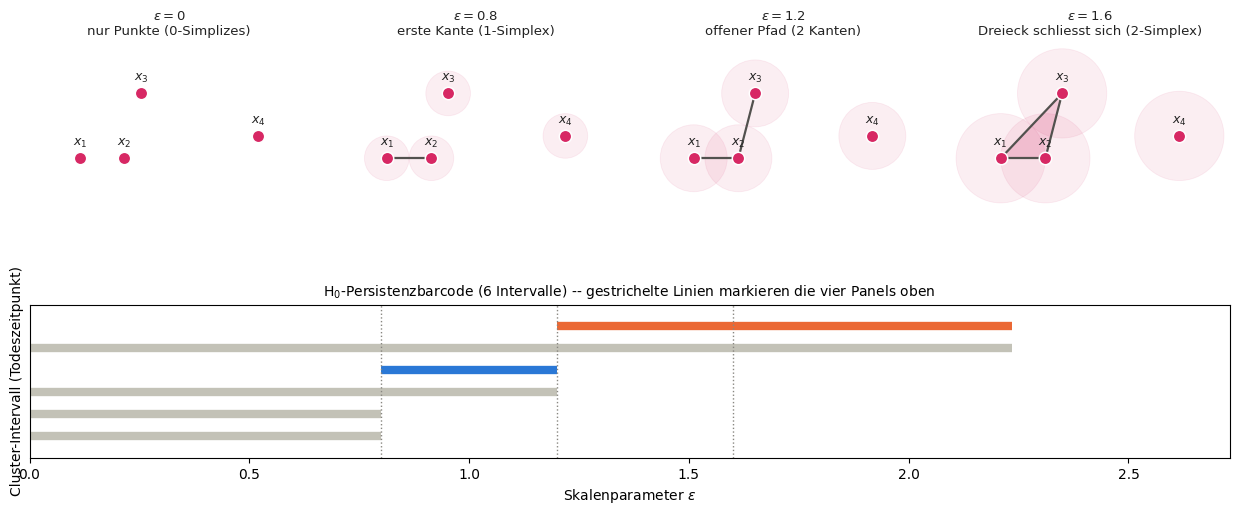

Gespeichert: /Users/ryanmikus/Development/Python/00_Quant/26FS_BA/images/vietoris_rips_barcode.png


In [18]:
from matplotlib.patches import Circle, Polygon
from scipy.spatial.distance import pdist, squareform

from src.clustering.plots import plot_h0_barcode_on_ax, _INK_MUTED, _INK_SECONDARY

# Vier abstrakte Punkte, keine Asset-Daten. x1-x2-x3 bilden ein bewusst nicht-
# gleichschenkliges (skalenes) Dreieck mit drei klar unterschiedlichen
# Seitenlaengen (0.8 / 1.2 / 1.6), sodass die drei Kanten bei drei
# unterschiedlichen Epsilon-Werten entstehen -- zuerst eine einzelne Kante
# (Linie), dann ein offener Pfad, erst danach das geschlossene Dreieck (statt
# dass sich bei einem gleichseitigen/gleichschenkligen Dreieck mehrere Kanten
# gleichzeitig verbinden wuerden). x4 liegt bewusst weiter entfernt (naechste
# Distanz zu x4 ist 2.23, weit ausserhalb des gezeigten Bereichs) und bleibt in
# allen vier Panels isoliert.
toy_points = np.array([
    [0.0, 0.0],
    [0.8, 0.0],
    [1.1, np.sqrt(1.35)],
    [3.2, 0.4],
])
n_toy = len(toy_points)
toy_labels = [f"$x_{{{i+1}}}$" for i in range(n_toy)]
toy_dist = squareform(pdist(toy_points))

# Vier Stufen, anhand der tatsaechlichen paarweisen Distanzen so gewaehlt, dass
# jede Stufe einen neuen strukturellen Schritt zeigt:
#   0.0 -> alle isoliert (0-Simplizes)
#   0.8 -> erste Kante x1-x2 (1-Simplex), noch kein Pfad
#   1.2 -> zusaetzlich Kante x2-x3: offener Pfad x1-x2-x3, noch kein Dreieck
#          (x1-x3 = 1.6, noch nicht erreicht)
#   1.6 -> zusaetzlich Kante x1-x3: Dreieck schliesst sich (2-Simplex)
# x4 bleibt in diesem Bereich isoliert (naechste Kante zu x4 waere bei 2.23).
toy_epsilons = [0.0, 0.8, 1.2, 1.6]
# +1e-9 Sicherheitsmarge gegen Floating-Point-Rauschen: sqrt(1.35) ist
# irrational, die resultierende Distanz x2-x3 liegt dadurch numerisch hauchduenn
# (~1e-16) ueber 1.2 -- ohne Marge wuerde die zweite Kante im eps=1.2-Panel
# faelschlich fehlen.
EPS_TOL = 1e-9
toy_show_radius = [False, True, True, True]
toy_titles = [
    r"$\epsilon=0$" + "\nnur Punkte (0-Simplizes)",
    r"$\epsilon=0.8$" + "\nerste Kante (1-Simplex)",
    r"$\epsilon=1.2$" + "\noffener Pfad (2 Kanten)",
    r"$\epsilon=1.6$" + "\nDreieck schliesst sich (2-Simplex)",
]

fig = plt.figure(figsize=(12.5, 5.6))
gs = fig.add_gridspec(2, 4, height_ratios=[1.15, 1.0], hspace=0.55, wspace=0.1,
                       top=0.86, bottom=0.11, left=0.03, right=0.99)

pad = 0.9
xlim = (toy_points[:, 0].min() - pad, toy_points[:, 0].max() + pad)
ylim = (toy_points[:, 1].min() - pad, toy_points[:, 1].max() + pad)

for col, (eps, radius_on) in enumerate(zip(toy_epsilons, toy_show_radius)):
    ax = fig.add_subplot(gs[0, col])

    # Kanten (1-Simplizes): Vietoris-Rips = Cluster-Komplex des epsilon-Distanzgraphen.
    for i in range(n_toy):
        for j in range(i + 1, n_toy):
            if toy_dist[i, j] <= eps + EPS_TOL:
                ax.plot([toy_points[i, 0], toy_points[j, 0]], [toy_points[i, 1], toy_points[j, 1]],
                        color=_INK_SECONDARY, linewidth=1.6, zorder=1)

    # Gefuellte Dreiecke (2-Simplizes): nur wenn ALLE DREI paarweisen Kanten <= epsilon.
    for i in range(n_toy):
        for j in range(i + 1, n_toy):
            for k in range(j + 1, n_toy):
                if (toy_dist[i, j] <= eps + EPS_TOL and toy_dist[i, k] <= eps + EPS_TOL
                        and toy_dist[j, k] <= eps + EPS_TOL):
                    ax.add_patch(Polygon(toy_points[[i, j, k]], closed=True,
                                          facecolor=OST_PINK, alpha=0.18, edgecolor="none", zorder=0))

    # Radius-Kreise (radius = epsilon/2): beruehren sich zwei Kreise, liegt eine Kante vor.
    if radius_on and eps > 0:
        for i in range(n_toy):
            ax.add_patch(Circle(toy_points[i], eps / 2, facecolor=OST_PINK, alpha=0.08,
                                 edgecolor=OST_PINK, linewidth=0.6, zorder=0.5))

    ax.scatter(toy_points[:, 0], toy_points[:, 1], s=80, color=OST_PINK, edgecolor="white",
               linewidth=1.1, zorder=2)
    for i, lbl in enumerate(toy_labels):
        ax.annotate(lbl, toy_points[i], textcoords="offset points", xytext=(0, 9),
                    ha="center", fontsize=9, color=TEXT_DARK)

    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    # ax.set_title(toy_titles[col], ...) bleibt bestehen: identifiziert, welche
    # Epsilon-Stufe dieses Panel zeigt -- noetige Panel-Beschriftung, keine
    # Dopplung der LaTeX-Abbildungsbeschriftung.
    ax.set_title(toy_titles[col], fontsize=9.5, color=TEXT_DARK)

ax_barcode = fig.add_subplot(gs[1, :])
n_bars = plot_h0_barcode_on_ax(toy_dist, [f"x{i+1}" for i in range(n_toy)], ax_barcode, x_max=2.6)
for eps in toy_epsilons[1:]:
    ax_barcode.axvline(eps, color=_INK_MUTED, linestyle=":", linewidth=1)
ax_barcode.set_xlabel(r"Skalenparameter $\epsilon$")
# ax_barcode.set_title(...) bleibt bestehen: unterscheidet dieses Panel
# (H0-Barcode) inhaltlich von den vier Filtrations-Panels darueber -- keine
# Dopplung der LaTeX-Abbildungsbeschriftung, sondern noetige Panel-Beschriftung.
ax_barcode.set_title(f"H$_0$-Persistenzbarcode ({n_bars} Intervalle) -- gestrichelte Linien markieren die vier Panels oben",
                      fontsize=10)

# Kein fig.suptitle(): Die Bachelorarbeit traegt die Beschreibung ueber die
# LaTeX-Abbildungsbeschriftung (\caption), ein zusaetzlicher Gesamttitel waere doppelt.
out_path = IMAGES_DIR / "vietoris_rips_barcode.png"
fig.savefig(out_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Gespeichert: {out_path}")
